# Lekcja 9. Algorytm Grovera

**Cel:** zrozumieć Grovera na macierzach w $\mathbb{C}^8$: czym jest wyrocznia, czym dyfuzja, dlaczego po dwóch iteracjach sekret ma 94,5%, a po trzech tylko 33%, i skąd bierze się przyspieszenie $\sqrt N$ zamiast $N$. To jest matematyka stojąca za Demo 1 z wystąpienia.

## 1. Problem

Mamy funkcję $f: \{0, \dots, N-1\} \to \{0, 1\}$, przy czym dokładnie jedno $w$ spełnia $f(w) = 1$. Nie znamy żadnej struktury $f$: możemy ją tylko wywoływać („czy to jest hasło?”).

- Klasycznie potrzeba średnio $N/2$ wywołań, w najgorszym razie $N - 1$ (ostatniego kandydata już nie trzeba sprawdzać).
- Koszt algorytmu liczymy **w wywołaniach $f$**. W wersji kwantowej jedno wywołanie $f$ to jedno użycie wyroczni.

W demie $N = 8$ (3 kubity), a $w$ to liczba wybrana przez publiczność. W przykładach poniżej $w = 5$, etykieta 101, czyli wektor $e_5 \in \mathbb{C}^8$.

## 2. Przestrzeń i stan początkowy

Stan 3 kubitów to wektor jednostkowy $v \in \mathbb{C}^8$: osiem współrzędnych, po jednej amplitudzie na każdy wynik 000, ..., 111 (lekcja 6).

> **To było trudne:** „każdy kubit ma stan 0 albo 1” to skrót, który prowadzi w złą stronę. **Wynik pomiaru** każdego kubitu to 0 albo 1, stąd $2^3 = 8$ możliwych wyników. **Stan** to dowolny wektor jednostkowy w $\mathbb{C}^8$. Osiem „klasycznych” stanów to tylko wektory bazowe $e_0, \dots, e_7$, a Grover działa właśnie na wektorach, które bazowe **nie są**.

Zaczynamy od $e_0 = e_0 \otimes e_0 \otimes e_0$ (schłodzony chip). Ten sam symbol $e_0$ oznacza tu wektor bazowy w $\mathbb{C}^8$ po lewej i w $\mathbb{C}^2$ po prawej; z kontekstu zawsze wiadomo który. Hadamard na każdym kubicie, czyli macierz $H \otimes H \otimes H$ (lekcja 5), daje

$$u = (H \otimes H \otimes H)\, e_0 = He_0 \otimes He_0 \otimes He_0 = \tfrac{1}{\sqrt8}(1, 1, 1, 1, 1, 1, 1, 1).$$

Wszystkie amplitudy są równe $a = 1/\sqrt8 \approx 0{,}354$, każdy wynik ma $P = 1/8$.

> **To było trudne:** komputer kwantowy **nie** „sprawdza wszystkich 8 odpowiedzi naraz”. Gdybyśmy zmierzyli $u$, dostalibyśmy losową liczbę, czyli zwykłe zgadywanie. Równa superpozycja to tylko punkt startowy; całą pracę robi dopiero interferencja w kolejnych krokach.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # etykieta |0⟩
e1 = np.array([0, 1], dtype=complex)   # etykieta |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Wypisz wektor stanu z etykietami bitów (etykieta = pozycja w zapisie dwójkowym)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  pozycja {k} ({format(k, f'0{n}b')}): amplituda {np.round(a, 3)}, P = {abs(a)**2:.3f}")

from functools import reduce
from fractions import Fraction
kron = lambda *ms: reduce(np.kron, ms)

n, N, w = 3, 8, 5
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
X = np.array([[0, 1], [1, 0]])
I2 = np.eye(2)
H3 = kron(H, H, H)          # macierz 8×8
E = np.eye(N)               # E[k] to wektor bazowy e_k

u = H3 @ E[0]
print("u =", u)
print("P =", np.abs(u) ** 2)

u = [0.354 0.354 0.354 0.354 0.354 0.354 0.354 0.354]
P = [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]

## 3. Wyrocznia: macierz diagonalna

$$O = I - 2\, e_w e_w^{T} = \operatorname{diag}(1, 1, 1, 1, 1, -1, 1, 1) \qquad (w = 5).$$

Na wektorach bazowych: $O e_x = (-1)^{f(x)} e_x$. Z liniowości dla dowolnego stanu $v$ wyrocznia zmienia znak **jednej** współrzędnej, $v_w$, i nic poza tym.

- $O$ jest unitarna (diagonalna z $\pm 1$) i jest swoją własną odwrotnością.
- **Prawdopodobieństwa się nie zmieniają**: $|-v_w|^2 = |v_w|^2$. To jest faza względna z lekcji 3: pomiar jej nie widzi. Sama wyrocznia, użyta nawet sto razy, nie daje żadnej informacji. Fazę „zobaczy” dopiero następny krok, dyfuzja.

In [2]:
O = E - 2 * np.outer(E[w], E[w])
print("przekątna O:", np.diag(O))
print("O unitarna:", np.allclose(O.T @ O, E))

v = O @ u
print("O u      =", v)
print("P po O   =", np.abs(v) ** 2, " <- bez zmian")

przekątna O: [ 1.  1.  1.  1.  1. -1.  1.  1.]
O unitarna: True
O u      = [ 0.354  0.354  0.354  0.354  0.354 -0.354  0.354  0.354]
P po O   = [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]  <- bez zmian

### Jak zbudować wyrocznię z bramek

Bramka CCZ zmienia znak tylko przy 111: $\mathrm{CCZ} = \operatorname{diag}(1, \dots, 1, -1)$. Żeby zmieniała znak przy dowolnym $w$, na chwilę „przemalowujemy” $w$ na 111: stawiamy $X$ na kubitach, gdzie $w$ ma bit 0.

$$O = X_S \cdot \mathrm{CCZ} \cdot X_S, \qquad S = \{\text{kubity, na których } w \text{ ma } 0\}.$$

Dla $w = 101$: $X_S = I \otimes X \otimes I$. Wtedy $e_5 \xrightarrow{X} e_7 \xrightarrow{\mathrm{CCZ}} -e_7 \xrightarrow{X} -e_5$, a np. $e_7 \xrightarrow{X} e_5 \xrightarrow{\mathrm{CCZ}} e_5 \xrightarrow{X} e_7$.

Tak zbudowana jest wyrocznia w `00_ibm.ipynb`. W PennyLane robi to jedna bramka, `qml.FlipSign`. (Samo CCZ to $H$ na trzecim kubicie, Toffoli, znowu $H$, bo $HXH = Z$.)

**Uwaga na kolejność bitów:** poniżej, jak w PennyLane, kubit 0 to **pierwszy** bit. Qiskit numeruje odwrotnie, dlatego w `00_ibm` indeksy są odwrócone.

In [3]:
CCZ = np.diag([1, 1, 1, 1, 1, 1, 1, -1])

def X_on(qubits):
    """X na wybranych kubitach, I na pozostałych (kubit 0 = pierwszy bit)."""
    return kron(*[X if q in qubits else I2 for q in range(n)])

for s in range(N):
    bits = format(s, "03b")
    zeros = [q for q in range(n) if bits[q] == "0"]
    O_s = X_on(zeros) @ CCZ @ X_on(zeros)
    assert np.allclose(O_s, E - 2 * np.outer(E[s], E[s]))
print("X_S · CCZ · X_S = I − 2 e_s e_sᵀ dla wszystkich 8 sekretów")

X_S · CCZ · X_S = I − 2 e_s e_sᵀ dla wszystkich 8 sekretów

### Prawdziwa wyrocznia nie zna odpowiedzi

> **To było trudne:** w demie budujemy wyrocznię, **znając** $w$. To skrót. W prawdziwym problemie wyrocznia to obwód, który **sprawdza** kandydata, np. liczy hash i porównuje z zapisanym. Nie zna $w$, tylko umie je rozpoznać.

Taki obwód liczy $f$ na dodatkowym kubicie (odwracalnie, bo bramki są unitarne):

$$U_f\,(e_x \otimes e_y) = e_x \otimes e_{y \oplus f(x)}.$$

Jeśli dodatkowy kubit ustawimy na $m = (e_0 - e_1)/\sqrt2$, to dodanie $f(x)$ zamienia się w pomnożenie przez $(-1)^{f(x)}$:

$$U_f\,(e_x \otimes m) = (-1)^{f(x)}\,(e_x \otimes m).$$

To jest **phase kickback**: znak „wraca” na kubity z danymi, a dodatkowy kubit się nie zmienia. Wychodzi ta sama macierz $O$. (W praktyce wyniki pośrednie obliczania $f$ trzeba jeszcze „odliczyć” z powrotem, więc jedno wywołanie wyroczni to mniej więcej dwa obliczenia $f$.) Dlatego jedno użycie wyroczni to jedno pełne obliczenie $f$, np. hasha, na komputerze kwantowym.

In [4]:
f = lambda x: int(x == w)
Uf = np.zeros((2 * N, 2 * N))
for x in range(N):
    for y in range(2):
        Uf[2 * x + (y ^ f(x)), 2 * x + y] = 1    # e_x ⊗ e_y = e_(2x+y)
print("U_f to permutacja (unitarna):", np.allclose(Uf.T @ Uf, np.eye(2 * N)))

m = np.array([1, -1]) / np.sqrt(2)
for x in range(N):
    vx = kron(E[x], m)
    sign = (Uf @ vx) @ vx
    print(f"x = {x} ({x:03b}):  U_f (e_x ⊗ m) = {sign:+.0f} · (e_x ⊗ m)")

U_f to permutacja (unitarna): True
x = 0 (000):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 1 (001):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 2 (010):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 3 (011):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 4 (100):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 5 (101):  U_f (e_x ⊗ m) = -1 · (e_x ⊗ m)
x = 6 (110):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)
x = 7 (111):  U_f (e_x ⊗ m) = +1 · (e_x ⊗ m)

## 4. Dyfuzja: odbicie względem średniej

$$D = 2\,u u^{T} - I.$$

Na współrzędnych działa bardzo prosto. Jeśli $\bar v$ to średnia współrzędnych $v$, to $u u^T v = \bar v \cdot (1, \dots, 1)$, więc

$$(Dv)_k = 2\bar v - v_k.$$

Każda współrzędna odbija się względem średniej. Kluczowa obserwacja: współrzędna leżąca daleko **pod** średnią (ta, której wyrocznia zmieniła znak) ląduje daleko **nad** nią. Dyfuzja zamienia fazę, której pomiar nie widzi, na różnicę modułów, którą widzi.

Jako obwód: $D = H^{\otimes 3}\,(2 e_0 e_0^{T} - I)\,H^{\otimes 3}$, bo $H^{\otimes 3} e_0 = u$ i $H^{\otimes 3}$ jest swoją odwrotnością. W PennyLane to `qml.GroverOperator`.

In [5]:
D = 2 * np.outer(u, u) - E
print("D = H3 (2 e0 e0ᵀ − I) H3:", np.allclose(D, H3 @ (2 * np.outer(E[0], E[0]) - E) @ H3))
print("D unitarna:", np.allclose(D.T @ D, E))

v = np.array([1, 2, 3, 4, 5, 6, 7, 8.0])
print("\nv        =", v, " średnia =", v.mean())
print("D v      =", D @ v)
print("2·śr − v =", 2 * v.mean() - v)

D = H3 (2 e0 e0ᵀ − I) H3: True
D unitarna: True

v        = [1. 2. 3. 4. 5. 6. 7. 8.]  średnia = 4.5
D v      = [8. 7. 6. 5. 4. 3. 2. 1.]
2·śr − v = [8. 7. 6. 5. 4. 3. 2. 1.]

## 5. Liczymy ręcznie dla $N = 8$

Jedna iteracja Grovera to $G = D\,O$. Oznaczmy $a = 1/\sqrt8$. Ze względu na symetrię wystarczą dwie liczby: amplituda każdej z 7 złych odpowiedzi i amplituda sekretu.

| | pozostałe 7 | sekret | średnia | $P(w)$ |
|---|---|---|---|---|
| start | $a$ | $a$ | | $1/8 = 0{,}125$ |
| po $O$ | $a$ | $-a$ | $3a/4$ | |
| po $D$ ($k = 1$) | $a/2$ | $5a/2$ | | $25/32 = 0{,}781$ |
| po $O$ | $a/2$ | $-5a/2$ | $a/8$ | |
| po $D$ ($k = 2$) | $-a/4$ | $11a/4$ | | $121/128 = 0{,}945$ |
| po $O$ | $-a/4$ | $-11a/4$ | $-9a/16$ | |
| po $D$ ($k = 3$) | $-7a/8$ | $13a/8$ | | $169/512 = 0{,}330$ |

Kontrola normy dla $k = 1$: $7 \cdot \tfrac14 \cdot \tfrac18 + \tfrac{25}{32} = \tfrac{7}{32} + \tfrac{25}{32} = 1$.

- Każda iteracja „przelewa” amplitudę z siedmiu złych odpowiedzi do sekretu.
- Przy $k = 2$ złe amplitudy przeskakują przez zero ($-a/4$). Przy $k = 3$ średnia jest już ujemna, odbicie działa w drugą stronę i amplituda sekretu spada. To jest „More is not better” z notatnika.

k = 0:  pozostałe =     1 · a,  sekret =     1 · a,  P(sekret) = 0.125
k = 1:  pozostałe =   1/2 · a,  sekret =   5/2 · a,  P(sekret) = 0.781
k = 2:  pozostałe =  -1/4 · a,  sekret =  11/4 · a,  P(sekret) = 0.945
k = 3:  pozostałe =  -7/8 · a,  sekret =  13/8 · a,  P(sekret) = 0.330

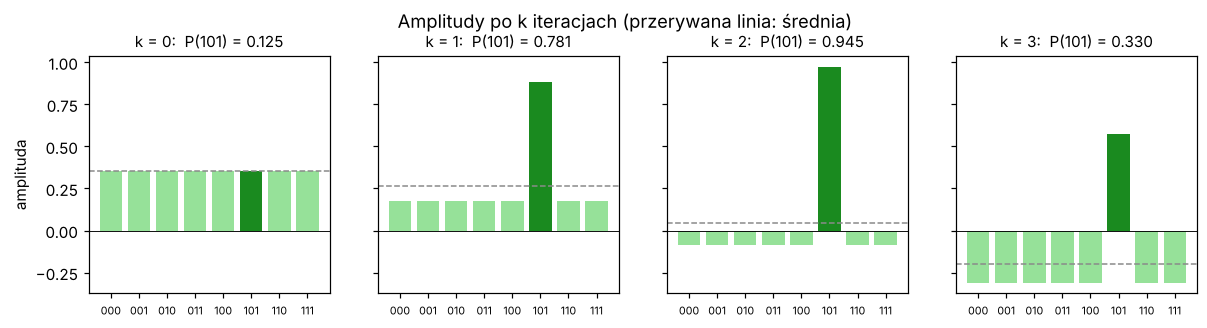

In [6]:
a = 1 / np.sqrt(N)
G = D @ O
v, states = u.copy(), []
for k in range(4):
    states.append(v.copy())
    other, sec = Fraction(v[0] / a).limit_denominator(64), Fraction(v[w] / a).limit_denominator(64)
    print(f"k = {k}:  pozostałe = {str(other):>5} · a,  sekret = {str(sec):>5} · a,  P(sekret) = {v[w] ** 2:.3f}")
    v = G @ v

fig, axs = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
labels = [format(k, "03b") for k in range(N)]
for k, (ax, s) in enumerate(zip(axs, states)):
    ax.bar(labels, s, color=[DARK if j == w else LIGHT for j in range(N)])
    ax.axhline(s.mean(), color=GREY, ls="--", lw=1)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"k = {k}:  P(101) = {s[w] ** 2:.3f}", fontsize=10)
    ax.tick_params(axis="x", labelsize=7)
axs[0].set_ylabel("amplituda")
fig.suptitle("Amplitudy po k iteracjach (przerywana linia: średnia)", y=1.03)

## 6. Geometria: dwa odbicia to obrót

Stan nigdy nie opuszcza płaszczyzny rozpiętej przez dwa ortonormalne wektory:

- $e_w$: sekret,
- $r = \frac{1}{\sqrt{N-1}} \sum_{k \ne w} e_k$: równa superpozycja złych odpowiedzi.

Stan początkowy leży w tej płaszczyźnie pod małym kątem $\theta$ od $r$:

$$u = \sin\theta\; e_w + \cos\theta\; r, \qquad \sin\theta = \frac{1}{\sqrt N}.$$

Dla $N = 8$: $\theta = \arcsin(1/\sqrt8) \approx 20{,}7^\circ$.

W tej płaszczyźnie obie macierze to **odbicia**:

- $O$ zmienia znak składowej przy $e_w$, a $r$ zostawia: odbicie względem prostej $r$;
- $D$ zostawia $u$ ($Du = 2u - u = u$), a wektor prostopadły do $u$ zmienia na przeciwny: odbicie względem prostej $u$.

Złożenie dwóch odbić względem prostych przecinających się pod kątem $\theta$ to **obrót o $2\theta$** (fakt z geometrii płaszczyzny). Po $k$ iteracjach stan jest pod kątem $(2k+1)\theta$ od $r$:

$$G^k u = \sin\big((2k+1)\theta\big)\, e_w + \cos\big((2k+1)\theta\big)\, r, \qquad P(w) = \sin^2\big((2k+1)\theta\big).$$

Kontrola z tabelą: $\sin 3\theta = 3\sin\theta - 4\sin^3\theta = \tfrac{3}{\sqrt8} - \tfrac{4}{8\sqrt8} = \tfrac{5}{2\sqrt8} = 5a/2$. Zgadza się.

In [7]:
r = (np.ones(N) - E[w]) / np.sqrt(N - 1)
theta = np.arcsin(1 / np.sqrt(N))
print(f"θ = {np.degrees(theta):.1f}°")
print("u = sinθ e_w + cosθ r:", np.allclose(u, np.sin(theta) * E[w] + np.cos(theta) * r))

B = np.column_stack([r, E[w]])          # baza płaszczyzny: r jako oś x, e_w jako oś y
G2 = B.T @ G @ B                        # G ograniczone do płaszczyzny: macierz 2×2
R = np.array([[np.cos(2 * theta), -np.sin(2 * theta)],
              [np.sin(2 * theta),  np.cos(2 * theta)]])
print("G w płaszczyźnie:\n", G2)
print("obrót o 2θ:\n", R)
print("równe:", np.allclose(G2, R))

θ = 20.7°
u = sinθ e_w + cosθ r: True
G w płaszczyźnie:
 [[ 0.75  -0.661]
 [ 0.661  0.75 ]]
obrót o 2θ:
 [[ 0.75  -0.661]
 [ 0.661  0.75 ]]
równe: True

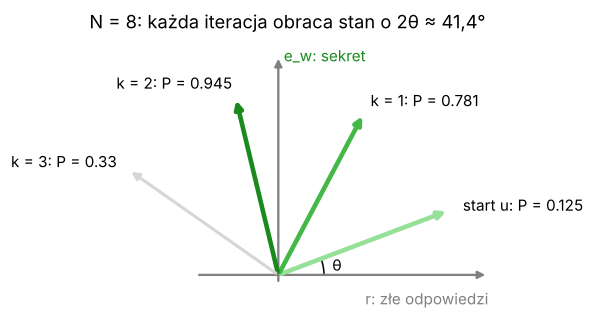

In [8]:
fig, ax = plt.subplots(figsize=(6, 5.4))
ax.set_aspect("equal"); ax.axis("off")
ax.annotate("", xy=(1.15, 0), xytext=(-0.45, 0), arrowprops=dict(arrowstyle="-|>", color="grey", lw=1.5))
ax.annotate("", xy=(0, 1.2), xytext=(0, -0.05), arrowprops=dict(arrowstyle="-|>", color="grey", lw=1.5))
ax.text(1.15, -0.08, "r: złe odpowiedzi", ha="right", va="top", color="grey")
ax.text(0.03, 1.2, "e_w: sekret", va="center", color=DARK)
shades = [LIGHT, GREEN, DARK, "#D6D6D6"]
for k in range(4):
    ang = (2 * k + 1) * theta
    ax.annotate("", xy=(np.cos(ang), np.sin(ang)), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=shades[k], lw=3 if k < 3 else 2))
    label = "start u" if k == 0 else f"k = {k}"
    ax.text(1.08 * np.cos(ang), 1.08 * np.sin(ang), f"{label}: P = {np.sin(ang) ** 2:.3g}",
            ha="left" if np.cos(ang) > 0.1 else "right", va="center", fontsize=10)
t = np.linspace(0, theta, 30)
ax.plot(0.25 * np.cos(t), 0.25 * np.sin(t), color="black", lw=1)
ax.text(0.3 * np.cos(theta / 2), 0.3 * np.sin(theta / 2), "θ", va="center")
ax.set_xlim(-1.35, 1.45); ax.set_ylim(-0.15, 1.3)
ax.set_title("N = 8: każda iteracja obraca stan o 2θ ≈ 41,4°")

## 7. Skąd $\sqrt N$

Żeby dojść do $e_w$, stan musi się obrócić o około $90^\circ$: $(2k+1)\theta \approx \pi/2$, czyli

$$k \approx \frac{\pi}{4\theta} - \frac12 \approx \frac{\pi}{4}\sqrt N,$$

bo dla dużego $N$ mamy $\theta \approx \sin\theta = 1/\sqrt N$. Liczba kroków rośnie jak $\sqrt N$ zamiast $N$: **przyspieszenie kwadratowe**.

- **To jest optimum.** Dla przeszukiwania bez struktury żaden algorytm kwantowy nie zrobi tego w mniej niż rząd $\sqrt N$ wywołań (Bennett, Bernstein, Brassard, Vazirani 1997). Grover nie łamie więc wszystkiego „wykładniczo szybciej”.
- **Trzeba wiedzieć, kiedy przestać.** Optymalne $k$ zależy od $N$ (i od liczby rozwiązań $M$: wtedy $\sin\theta = \sqrt{M/N}$). Za dużo iteracji to obrót za cel.
- **Liczba kroków to nie czas.** Dla hasła ze slajdu 9 ($26^{10} \approx 1{,}4 \cdot 10^{14}$) to około 9,3 mln iteracji, ale każda to pełne obliczenie hasha na komputerze kwantowym z korekcją błędów, wykonywane jedno po drugim. Grover słabo się zrównolegla ($K$ maszyn daje tylko $\sqrt K$). GPU sprawdza miliardy haseł na sekundę i w tym przykładzie wygrywa.

In [9]:
print(f"{'N':>22} {'klasycznie (najgorzej)':>24} {'optymalne k':>12} {'P(w)':>7}")
for label, NN in [("8", 8), ("64", 64), ("1024", 1024), ("1 milion", 10 ** 6), ("26^10", 26 ** 10)]:
    th = np.arcsin(1 / np.sqrt(float(NN)))
    k = int(np.floor(np.pi / (4 * th)))
    print(f"{label:>22} {float(NN):>24.3g} {k:>12,} {np.sin((2 * k + 1) * th) ** 2:>7.3f}")

                     N   klasycznie (najgorzej)  optymalne k    P(w)
                     8                        8            2   0.945
                    64                       64            6   0.997
                  1024                 1.02e+03           25   0.999
              1 milion                    1e+06          785   1.000
                 26^10                 1.41e+14    9,331,610   1.000

## 8. Na prawdziwym sprzęcie

Symulator bez szumu daje dla $k = 2$ dokładnie $121/128 \approx 94{,}5\%$. Na ibm_marrakesh (27 listopada 2026, 1000 shotów na każdy z 8 możliwych sekretów) sekret wypadł w 758–820 przypadkach na 1000. Po transpilacji obwód ma 45 bramek dwukubitowych, a każda dokłada trochę szumu (lekcja 5: sprzęt to nie jest układ zamknięty). Mimo to sekret jest wyraźnie widoczny: druga najczęstsza odpowiedź ma najwyżej 65 trafień.

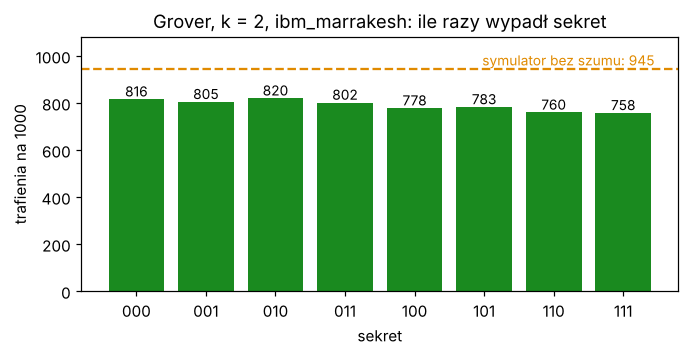

In [10]:
ibm = {0: 816, 1: 805, 2: 820, 3: 802, 4: 778, 5: 783, 6: 760, 7: 758}
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([format(s, "03b") for s in ibm], ibm.values(), color=DARK)
ax.axhline(1000 * 121 / 128, color=ORANGE, ls="--")
ax.text(7.45, 960, "symulator bez szumu: 945", ha="right", color=ORANGE, fontsize=9)
for i, c in enumerate(ibm.values()):
    ax.text(i, c + 12, c, ha="center", fontsize=9)
ax.set_ylim(0, 1080); ax.set_xlabel("sekret"); ax.set_ylabel("trafienia na 1000")
ax.set_title("Grover, k = 2, ibm_marrakesh: ile razy wypadł sekret")

## Podsumowanie

> Grover to na zmianę dwie macierze: wyrocznia $O$ zmienia znak współrzędnej sekretu (faza, której pomiar nie widzi), a dyfuzja $D$ odbija wszystkie współrzędne względem średniej i zamienia tę fazę na wzrost amplitudy. Geometrycznie to dwa odbicia w płaszczyźnie $(e_w, r)$, czyli obrót o $2\theta$, gdzie $\sin\theta = 1/\sqrt N$. Do sekretu trzeba obrócić się o około $90^\circ$, więc potrzeba około $(\pi/4)\sqrt N$ iteracji zamiast $N$ prób: przyspieszenie kwadratowe, optymalne, ale nie wykładnicze. Za dużo iteracji obraca stan za cel.

**Zdania na scenę:**

- „Wyrocznia nie zna odpowiedzi, tylko umie ją rozpoznać: odwraca znak amplitudy tam, gdzie sprawdzenie wychodzi pozytywnie.”
- „Zaczynamy od równej superpozycji; wyrocznia i dyfuzja krok po kroku przesuwają amplitudę w stronę sekretu.”
- „Każda iteracja to obrót o ten sam kąt. Dwie iteracje trafiają prawie w cel, trzecia już go mija.”
- „√N zamiast N to dużo, ale nie wszystko: każdy krok to pełne sprawdzenie na komputerze kwantowym.”

## Zadania

1. Policz ręcznie $P(w)$ po jednej iteracji dla $N = 4$. Co wychodzi i dlaczego? (Wskazówka: $\theta = 30^\circ$.)
2. Pokaż, że $D u = u$ i że $D v = -v$ dla każdego $v \perp u$.
3. Dlaczego sama wyrocznia, użyta dowolnie wiele razy bez $D$, nie zmienia rozkładu wyników?
4. Ile iteracji jest optymalnych dla $N = 16$? Jakie jest wtedy $P(w)$? Sprawdź kodem.
5. Zbuduj $X_S \cdot \mathrm{CCZ} \cdot X_S$ dla $w = 010$. Na których kubitach stoją bramki $X$?